# 10D — Scouting Decision Simulator: demonstration on real cases

**What it simulates.** The scouting REVIEW workflow — question → prospects → evidence → action → report. Not a draft, not a game, not an outcome. Every line of the action comes from a deterministic rule in `decision_simulator.simulate` on stored mart values and carries one of five evidence categories: *measured difference · uncertain difference · missing observation · measurement mismatch · additional data needed*.

**Scenarios.** Five scouting questions on the athletes of the 10B stories (when 10B has run in this mode; otherwise on the first 09D cases). None is chosen on an NFL outcome.

**Prerequisites.** 09E mart, 10A passed; 10B optional (provides the story athletes). **Writes.** `reports/milestone10/decision_reports/*.html|pdf` (scout, position coach, general manager), figure `AM10D_01_decision_workflow`, `product_v1/decision_demonstration.json`.

In [1]:
RUN_MODE = 'full'             # 'smoke' | 'full'
SEED = 20261011
FORCE_REBUILD = False
SAVE_TABLES = True
SAVE_FIGURES = True
NUM_WORKERS = 0
WRITE_PDF = True              # text PDFs of the three audience reports (matplotlib)

In [2]:
from nflbdb.data.config import Phase01Config, configure_runtime

cfg = Phase01Config.load()
configure_runtime(cfg)

import polars as pl
from IPython.display import Markdown, display

from nflbdb.data.utils import utc_now
from nflbdb.research.advanced_movement import config as amc
from nflbdb.research.advanced_movement import decision_simulator as ds
from nflbdb.research.advanced_movement import final_figures as ff
from nflbdb.research.advanced_movement import milestone09_artifacts as m9
from nflbdb.research.advanced_movement import movement_gap as mg
from nflbdb.research.advanced_movement.artifacts import MissingArtifactError, ProductStore

controls = amc.NotebookControls(run_mode=RUN_MODE, force_rebuild=FORCE_REBUILD, save_figures=SAVE_FIGURES, save_tables=SAVE_TABLES,
                                seed=SEED, num_workers=NUM_WORKERS).validate()
store = ProductStore(cfg, controls)
MART = m9.mart_path(store)
m9.assert_valid(m9.validate_mart(MART))
T, EVID, MANIFEST = m9.load_mart(MART)
OUT = store.reports_dir / 'decision_reports'
OUT.mkdir(parents=True, exist_ok=True)
PROF = {r['nfl_id']: r for r in T['prospect_profiles'].iter_rows(named=True)}
TWD = {t['pair_id']: t for t in T['stopwatch_twins'].to_dicts()}
REG, EVR = T['nfl_demand_registry'].to_dicts(), T['feature_evidence'].to_dicts()
G = mg.gap_matrix(REG, T['nfl_movement_demands'].to_dicts(), T['movement_matching_summary'].to_dicts())
FOOTER = f'Combine Intelligence Lab · mart {MANIFEST["mart_version"]} built {MANIFEST["built_at"]} · run mode {controls.run_mode} · notebook 10D'

def run(question, a_id, b_id=None):
    a, b = PROF[a_id], (PROF[b_id] if b_id is not None else None)
    twin, diffs = None, []
    if b_id is not None:
        row = next((t for t in TWD.values() if {t['nfl_id_a'], t['nfl_id_b']} == {a_id, b_id}), None)
        if row:
            raw = T['twin_differences'].filter(pl.col('pair_id') == row['pair_id']).sort('feature').to_dicts()
            twin, diffs = ds.orient_pair(row, raw, a_id)
    pos = a['position_group']
    return ds.simulate(question, a, T['prospect_metrics'].filter(pl.col('nfl_id') == a_id).sort('feature').to_dicts(), b=b,
                       metrics_b=T['prospect_metrics'].filter(pl.col('nfl_id') == b_id).sort('feature').to_dicts() if b_id is not None else (),
                       twin=twin, diffs=diffs, matrix_a=T['movement_similarity_matrix'].filter(pl.col('nfl_id') == a_id).to_dicts(),
                       demands=T['nfl_movement_demands'].filter(pl.col('position_group') == pos).to_dicts(), registry=REG, evidence=EVR, gap=G)

label = 'SMOKE — wiring check, numbers are not results' if controls.smoke else 'FULL'
display(Markdown(f'**Run mode: `{controls.run_mode}`** ({label}) · mart built {MANIFEST["built_at"]}'))

**Run mode: `full`** (FULL) · mart built 2026-10-14T13:13:05Z

## 1 · The workflow

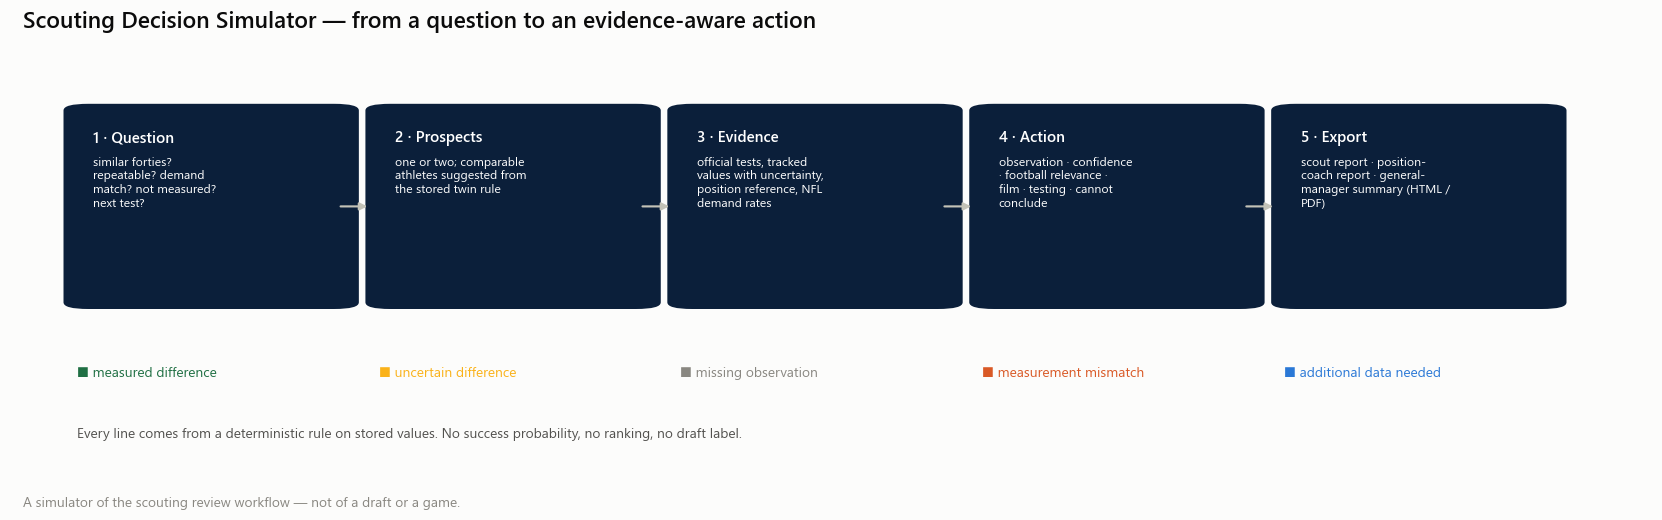

question_id,question,athletes
str,str,i64
"""twins_differ""","""Two prospects have similar for…",2
"""repeatable_advantage""","""Is a tracked acceleration diff…",2
"""demand_correspondence""","""Which parts of a measured prof…",1
"""not_measured""","""Which relevant physical qualit…",1
"""follow_up_testing""","""What follow-up testing would r…",1


In [3]:
store.show(ff.fig_decision_workflow(), 'AM10D_01_decision_workflow', {}, publication=True, source='decision_simulator (diagram)', n='—')
display(pl.DataFrame([{'question_id': k, 'question': v['text'], 'athletes': v['athletes']} for k, v in ds.QUESTIONS.items()]))

## 2 · Five scenarios on real athletes

In [4]:
try:
    S10B = store.read_json('signature_stories', '10b_signature_football_stories.ipynb')['stories']
except MissingArtifactError:
    S10B = {}
pair_of = lambda k: (TWD[S10B[k]['provenance']['pair_id']]['nfl_id_a'], TWD[S10B[k]['provenance']['pair_id']]['nfl_id_b']) if k in S10B else None
cases = T['scouting_cases'].to_dicts()
sf = pair_of('same_forty') or ((cases[0]['nfl_id_a'], cases[0]['nfl_id_b']) if cases else None)
wr = pair_of('wr') or ((cases[1]['nfl_id_a'], cases[1]['nfl_id_b']) if len(cases) > 1 else sf)
gap_pos = S10B['gap']['card']['position'] if 'gap' in S10B else (mg.gap_position(mg.gap_summary(G)) or {}).get('position_group')
gp = next((i for c in cases for i in (c['nfl_id_a'], c['nfl_id_b']) if PROF[i]['position_group'] == gap_pos and PROF[i]['n_tracked_attempts'] > 0), sf[0] if sf else None)
SCEN = [s for s in [('twins_differ', *sf) if sf else None, ('repeatable_advantage', *wr) if wr else None, ('demand_correspondence', sf[0], None) if sf else None,
                    ('not_measured', gp, None) if gp else None, ('follow_up_testing', wr[1], None) if wr else None] if s]
display(pl.DataFrame([{'question': q, 'A': PROF[a]['display_name'], 'B': PROF[b]['display_name'] if b else '—', 'position': PROF[a]['position_group']} for q, a, b in SCEN]))

question,A,B,position
str,str,str,str
"""twins_differ""","""Anthony Bradford""","""Mason McCormick""","""OL"""
"""repeatable_advantage""","""Ladd McConkey""","""Isaiah Bond""","""WR"""
"""demand_correspondence""","""Anthony Bradford""","""—""","""OL"""
"""not_measured""","""Ladd McConkey""","""—""","""WR"""
"""follow_up_testing""","""Isaiah Bond""","""—""","""WR"""


In [5]:
RESULTS = []
for q, a, b in SCEN:
    r = run(q, a, b)
    RESULTS.append(r)
    md = [f"### {r['question']} — {' vs '.join(r['athletes'])} ({r['position_group']})", '', f"**Decision support:** {r['decision']}", '',
          '**Evidence categories:** ' + ', '.join(f'{ds.CATEGORIES[k]} {v}' for k, v in r['category_counts'].items() if v and k != 'context'), '']
    for sec in ds.SECTIONS:
        md += [f'**{sec}**'] + [(f"- *[{ds.CATEGORIES[x['category']]}]* {x['text']}" if x['category'] != 'context' else f"- {x['text']}") for x in r['sections'][sec]] + ['']
    display(Markdown('\n'.join(md)))

### Two prospects have similar forty times. What else differs? — Anthony Bradford vs Mason McCormick (OL)

**Decision support:** Additional evaluation is supported — as film review and a targeted test of the named phase(s), not as an input for ranking.

**Evidence categories:** Measured difference 3, Uncertain difference 4, Missing observation 1, Additional data needed 6

**Observation**
- Anthony Bradford (OL, class 2023): official forty 5.08 s, 10-yard split 1.74 s, weight 332 lb.
- Mason McCormick (OL, class 2024): official forty 5.08 s, 10-yard split 1.71 s, weight 309 lb.
- Matched by the stored rule: same position, official forty 0.00 s apart, 10-yard split 0.03 s apart.
- *[Uncertain difference]* Initial acceleration: band acceleration 2 → 4 yd/s 4.60 (Anthony Bradford) vs 9.43 (Mason McCormick) yd/s², difference +4.83 [+3.77, +5.89] — inside its measurement uncertainty — not a difference.
- *[Measured difference]* Early speed development: speed at 10 yd 7.59 (Anthony Bradford) vs 9.10 (Mason McCormick) yd/s, difference +1.51 [+1.23, +1.79] — larger than its measurement uncertainty. On this measure the observed value favours Mason McCormick.
- *[Measured difference]* Intermediate speed development: band acceleration 6 → 8 yd/s 1.90 (Anthony Bradford) vs 6.05 (Mason McCormick) yd/s², difference +4.15 [+3.39, +4.91] — larger than its measurement uncertainty. On this measure the observed value favours Mason McCormick.
- *[Uncertain difference]* Late sprint: speed at 30 yd 9.30 (Anthony Bradford) vs 9.23 (Mason McCormick) yd/s, difference -0.07 [-0.24, +0.10] — inside its measurement uncertainty — not a difference.
- *[Measured difference]* Maximum tracked speed: tracked top speed (p95) 9.34 (Anthony Bradford) vs 9.56 (Mason McCormick) yd/s, difference +0.22 [+0.04, +0.40] — larger than its measurement uncertainty. On this measure the observed value favours Mason McCormick.

**Confidence**
- 5 of 8 tested feature(s) differ by more than the uncertainty of the difference (repeat-attempt variation of both athletes; about 5 % of features would by chance alone).
- *[Uncertain difference]* Distinguishable but on a feature not repeatable enough to describe an athlete: band acceleration 2 → 4 yd/s, band acceleration 4 → 6 yd/s.
- *[Uncertain difference]* Mason McCormick: recording evidence tier 'low'. Recording evidence is below the high tier: the measurement is shown, with that caveat.
- Largely the same information as official testing: speed at 20 yd.

**Potential football relevance**
- *[Missing observation]* The NFL demand closest to late acceleration and high speed (above about 6 yd/s) ('transition_high'): Too few observed NFL episodes for this position and demand to describe it (support rule of the 09A atlas).
- OL athletes show 81.4 'acceleration from low speed' episodes per 100 eligible player-plays (67,409 episodes, 90 athletes) — the observed game demand physically closest to early acceleration (first steps, below about 4 yd/s).
- OL athletes show 2.7 'acceleration from intermediate speed' episodes per 100 eligible player-plays (2,208 episodes, 83 athletes) — the observed game demand physically closest to mid-sprint speed development (about 4 to 8 yd/s).
- A physical correspondence only: the football advantage of the measured difference has not been established.

**Next film review**
- *[Additional data needed]* Film — compare Anthony Bradford and Mason McCormick on screens and long pursuit after a turnover (late acceleration and high speed (above about 6 yd/s)).
- *[Additional data needed]* Film — compare Anthony Bradford and Mason McCormick on the first steps of a pull or a set (early acceleration (first steps, below about 4 yd/s)).
- *[Additional data needed]* Film — compare Anthony Bradford and Mason McCormick on pulls and climbs to the second level (mid-sprint speed development (about 4 to 8 yd/s)).

**Additional testing**
- *[Additional data needed]* Late acceleration and high speed (above about 6 yd/s) — a longer sprint or flying 20-yard segment, because 40 yards can end before top speed is reached.
- *[Additional data needed]* Early acceleration (first steps, below about 4 yd/s) — timed starts over 0–5 and 0–10 yd with split timing, at least two repetitions, recorded from before the first movement.
- *[Additional data needed]* Mid-sprint speed development (about 4 to 8 yd/s) — rolling-start (flying) 10-yard segments entered at a controlled speed, so the 4 → 8 yd/s band is measured directly.
- A proposed test is a candidate way to measure a demand the forty does not describe. Its value for evaluating NFL prospects has not been established and would need prospective evidence.

**Cannot conclude**
- Which prospect will perform better in the NFL: no tracked Combine feature improved held-out prediction of NFL movement (Milestone 06) or receiver separation (Milestone 08B) beyond official testing.
- A draft order or a value judgement: the Lab describes measurements and does not rank prospects.
- That a physical similarity to an NFL demand means the demand will be met in pads, in traffic or late in a game.
- That a measured Combine difference causes a football outcome, or that training it would change one.


### Is a tracked acceleration difference repeatable? — Ladd McConkey vs Isaiah Bond (WR)

**Decision support:** Tracking adds no measured difference here: evaluate on film and official testing as usual.

**Evidence categories:** Uncertain difference 7

**Observation**
- Ladd McConkey (WR, class 2024): official forty 4.39 s, 10-yard split 1.52 s, weight 186 lb.
- Isaiah Bond (WR, class 2025): official forty 4.39 s, 10-yard split 1.51 s, weight 180 lb.
- Matched by the stored rule: same position, official forty 0.00 s apart, 10-yard split 0.01 s apart.
- *[Uncertain difference]* Initial acceleration: band acceleration 2 → 4 yd/s 6.95 (Ladd McConkey) vs 5.23 (Isaiah Bond) yd/s², difference -1.72 [-3.05, -0.40] — inside its measurement uncertainty — not a difference.
- *[Uncertain difference]* Early speed development: band acceleration 4 → 6 yd/s 5.61 (Ladd McConkey) vs 4.95 (Isaiah Bond) yd/s², difference -0.66 [-1.95, +0.63] — inside its measurement uncertainty — not a difference.
- *[Uncertain difference]* Intermediate speed development: speed development 4 → 8 yd/s 0.79 (Ladd McConkey) vs 0.93 (Isaiah Bond) s, difference +0.14 [-0.01, +0.29] — inside its measurement uncertainty — not a difference.

**Confidence**
- 0 of 4 tested feature(s) differ by more than the uncertainty of the difference (repeat-attempt variation of both athletes; about 5 % of features would by chance alone).
- *[Uncertain difference]* Distinguishable but on a feature not repeatable enough to describe an athlete: band acceleration 2 → 4 yd/s.
- *[Uncertain difference]* Ladd McConkey: recording evidence tier 'low'. Recording evidence is below the high tier: the measurement is shown, with that caveat.
- *[Uncertain difference]* band acceleration 2 → 4 yd/s as a measurement: repeat-attempt ICC 0.35 (unstable); R² on official times 0.08 (partly_beyond_stopwatch).
- *[Uncertain difference]* band acceleration 4 → 6 yd/s as a measurement: repeat-attempt ICC 0.49 (unstable); R² on official times 0.29 (partly_beyond_stopwatch).
- band acceleration 6 → 8 yd/s as a measurement: repeat-attempt ICC 0.61 (moderately_repeatable); R² on official times 0.47 (partly_beyond_stopwatch).
- speed development 4 → 8 yd/s as a measurement: repeat-attempt ICC 0.82 (repeatable); R² on official times 0.65 (partly_beyond_stopwatch).

**Potential football relevance**

**Next film review**
- No tracking-based film prompt: review the prospect(s) on film and official testing as usual.

**Additional testing**
- A proposed test is a candidate way to measure a demand the forty does not describe. Its value for evaluating NFL prospects has not been established and would need prospective evidence.

**Cannot conclude**
- Which prospect will perform better in the NFL: no tracked Combine feature improved held-out prediction of NFL movement (Milestone 06) or receiver separation (Milestone 08B) beyond official testing.
- A draft order or a value judgement: the Lab describes measurements and does not rank prospects.
- That a physical similarity to an NFL demand means the demand will be met in pads, in traffic or late in a game.
- That a measured Combine difference causes a football outcome, or that training it would change one.


### Which parts of a measured profile correspond to common NFL movement demands? — Anthony Bradford (OL)

**Decision support:** Tracking adds no measured difference here: evaluate on film and official testing as usual.

**Evidence categories:** Uncertain difference 3, Missing observation 1, Measurement mismatch 7, Additional data needed 6

**Observation**
- Anthony Bradford (OL, class 2023): official forty 5.08 s, 10-yard split 1.74 s, weight 332 lb.
- *[Uncertain difference]* Anthony Bradford — band acceleration 2 → 4 yd/s: 4.60 yd/s² ± 0.61; raw position percentile 44 of 94 (for times, lower = quicker).
- *[Uncertain difference]* Anthony Bradford — band acceleration 4 → 6 yd/s: 3.73 yd/s² ± 0.61; raw position percentile 28 of 94 (for times, lower = quicker).
- Anthony Bradford — band acceleration 6 → 8 yd/s: 1.90 yd/s² ± 0.54; raw position percentile 32 of 94 (for times, lower = quicker).
- Anthony Bradford — speed at 10 yd: 7.59 yd/s ± 0.20; raw position percentile 23 of 94 (for times, lower = quicker).
- Anthony Bradford — speed at 20 yd: 9.11 yd/s ± 0.11; raw position percentile 74 of 94 (for times, lower = quicker).
- Anthony Bradford — speed at 30 yd: 9.30 yd/s ± 0.12; raw position percentile 52 of 94 (for times, lower = quicker).
- Anthony Bradford — speed development 4 → 8 yd/s: 1.59 s ± 0.15; raw position percentile 67 of 94 (for times, lower = quicker).
- Anthony Bradford — tracked top speed (p95): 9.34 yd/s ± 0.12; raw position percentile 49 of 94 (for times, lower = quicker).

**Confidence**
- Anthony Bradford — band acceleration 2 → 4 yd/s: range 4.48–4.71 yd/s² over 2 attempts.
- Anthony Bradford — band acceleration 4 → 6 yd/s: range 3.72–3.73 yd/s² over 2 attempts.
- Anthony Bradford — band acceleration 6 → 8 yd/s: range 1.84–1.95 yd/s² over 2 attempts.
- Anthony Bradford — speed at 10 yd: range 7.56–7.63 yd/s over 2 attempts.
- *[Uncertain difference]* Not repeatable enough to describe an athlete: band acceleration 2 → 4 yd/s, band acceleration 4 → 6 yd/s.
- Anthony Bradford: recording evidence tier 'high'.

**Potential football relevance**
- OL athletes show 81.4 'acceleration from low speed' episodes per 100 eligible player-plays (67,409 episodes, 90 athletes) — the observed game demand physically closest to early acceleration (first steps, below about 4 yd/s).
- *[Missing observation]* The NFL demand closest to late acceleration and high speed (above about 6 yd/s) ('transition_high'): Too few observed NFL episodes for this position and demand to describe it (support rule of the 09A atlas).
- OL athletes show 2.7 'acceleration from intermediate speed' episodes per 100 eligible player-plays (2,208 episodes, 83 athletes) — the observed game demand physically closest to mid-sprint speed development (about 4 to 8 yd/s).
- A physical correspondence only: the football advantage of the measured difference has not been established.
- Anthony Bradford — acceleration from low speed: Combine value at or above 99 % of observed NFL episodes of the position [95, 100] over 2 shared dimension(s). Descriptive similarity, not a prediction.
- Anthony Bradford — acceleration from intermediate speed: Combine value at or above 100 % of observed NFL episodes of the position [100, 100] over 1 shared dimension(s). Descriptive similarity, not a prediction.
- *[Measurement mismatch]* braking and deceleration: This NFL movement demand has no physical analogue in the forty-yard dash. The Lab makes no statement about it.
- *[Measurement mismatch]* acceleration following deceleration: This NFL movement demand has no physical analogue in the forty-yard dash. The Lab makes no statement about it.
- *[Measurement mismatch]* directional redirection: This NFL movement demand has no physical analogue in the forty-yard dash. The Lab makes no statement about it.
- *[Measurement mismatch]* repeated speed-change sequence: This NFL movement demand has no physical analogue in the forty-yard dash. The Lab makes no statement about it.
- *[Measurement mismatch]* speed maintenance: This NFL movement demand has no physical analogue in the forty-yard dash. The Lab makes no statement about it.
- Anthony Bradford — sustained high-speed running: Combine value at or above 100 % of observed NFL episodes of the position [100, 100] over 1 shared dimension(s). Descriptive similarity, not a prediction.
- *[Measurement mismatch]* acceleration from intermediate speed (partially physically comparable): 2.7 episodes per 100 eligible OL player-plays (83 athletes) — same dimension(s) acc_4_6, acc_6_8, different movement state — same speed bands; in the forty the athlete passes through the band once, already accelerating.
- *[Measurement mismatch]* sustained high-speed running (partially physically comparable): 0.1 episodes per 100 eligible OL player-plays (29 athletes) — same dimension(s) top_speed, different movement state — largest speed reached: tracked top speed of the forty against the peak speed of the episode.

**Next film review**
- *[Additional data needed]* Film — review Anthony Bradford on the first steps of a pull or a set (early acceleration (first steps, below about 4 yd/s)).
- *[Additional data needed]* Film — review Anthony Bradford on screens and long pursuit after a turnover (late acceleration and high speed (above about 6 yd/s)).
- *[Additional data needed]* Film — review Anthony Bradford on pulls and climbs to the second level (mid-sprint speed development (about 4 to 8 yd/s)).

**Additional testing**
- *[Additional data needed]* Early acceleration (first steps, below about 4 yd/s) — timed starts over 0–5 and 0–10 yd with split timing, at least two repetitions, recorded from before the first movement.
- *[Additional data needed]* Late acceleration and high speed (above about 6 yd/s) — a longer sprint or flying 20-yard segment, because 40 yards can end before top speed is reached.
- *[Additional data needed]* Mid-sprint speed development (about 4 to 8 yd/s) — rolling-start (flying) 10-yard segments entered at a controlled speed, so the 4 → 8 yd/s band is measured directly.
- A proposed test is a candidate way to measure a demand the forty does not describe. Its value for evaluating NFL prospects has not been established and would need prospective evidence.

**Cannot conclude**
- Which prospect will perform better in the NFL: no tracked Combine feature improved held-out prediction of NFL movement (Milestone 06) or receiver separation (Milestone 08B) beyond official testing.
- A draft order or a value judgement: the Lab describes measurements and does not rank prospects.
- That a physical similarity to an NFL demand means the demand will be met in pads, in traffic or late in a game.
- That a measured Combine difference causes a football outcome, or that training it would change one.


### Which relevant physical qualities does the forty not measure? — Ladd McConkey (WR)

**Decision support:** The forty does not describe these demands: a targeted test is the way to observe them; the Combine data alone cannot.

**Evidence categories:** Uncertain difference 4, Measurement mismatch 2, Additional data needed 9

**Observation**
- Ladd McConkey (WR, class 2024): official forty 4.39 s, 10-yard split 1.52 s, weight 186 lb.
- *[Uncertain difference]* Ladd McConkey — band acceleration 2 → 4 yd/s: 6.95 yd/s² ± 0.94; raw position percentile 99 of 93 (for times, lower = quicker).
- *[Uncertain difference]* Ladd McConkey — band acceleration 4 → 6 yd/s: 5.61 yd/s² ± 0.91; raw position percentile 68 of 93 (for times, lower = quicker).
- Ladd McConkey — band acceleration 6 → 8 yd/s: 4.80 yd/s² ± 0.77; raw position percentile 96 of 93 (for times, lower = quicker).
- Ladd McConkey — speed at 10 yd: 9.28 yd/s ± 0.29; raw position percentile 97 of 93 (for times, lower = quicker).
- Ladd McConkey — speed at 20 yd: 10.29 yd/s ± 0.12; raw position percentile 54 of 93 (for times, lower = quicker).
- Ladd McConkey — speed at 30 yd: 10.87 yd/s ± 0.12; raw position percentile 42 of 93 (for times, lower = quicker).
- Ladd McConkey — speed development 4 → 8 yd/s: 0.79 s ± 0.10; raw position percentile 11 of 93 (for times, lower = quicker).
- Ladd McConkey — tracked top speed (p95): 10.93 yd/s ± 0.13; raw position percentile 34 of 93 (for times, lower = quicker).

**Confidence**
- Ladd McConkey — band acceleration 2 → 4 yd/s: range 4.78–9.12 yd/s² over 2 attempts.
- Ladd McConkey — band acceleration 4 → 6 yd/s: range 4.40–6.83 yd/s² over 2 attempts.
- Ladd McConkey — band acceleration 6 → 8 yd/s: range 4.59–5.01 yd/s² over 2 attempts.
- Ladd McConkey — speed at 10 yd: range 9.04–9.51 yd/s over 2 attempts.
- *[Uncertain difference]* Not repeatable enough to describe an athlete: band acceleration 2 → 4 yd/s, band acceleration 4 → 6 yd/s.
- *[Uncertain difference]* Ladd McConkey: recording evidence tier 'low'. Recording evidence is below the high tier: the measurement is shown, with that caveat.

**Potential football relevance**
- *[Measurement mismatch]* sustained high-speed running (partially physically comparable): 26.7 episodes per 100 eligible WR player-plays (82 athletes) — same dimension(s) top_speed, different movement state — largest speed reached: tracked top speed of the forty against the peak speed of the episode.
- *[Measurement mismatch]* acceleration from intermediate speed (partially physically comparable): 6.8 episodes per 100 eligible WR player-plays (80 athletes) — same dimension(s) acc_4_6, acc_6_8, different movement state — same speed bands; in the forty the athlete passes through the band once, already accelerating.

**Next film review**
- *[Additional data needed]* Film — review Ladd McConkey on releases at the line and the first three steps of short movements (early acceleration (first steps, below about 4 yd/s)).
- *[Additional data needed]* Film — review Ladd McConkey on vertical movements and long runs after the catch (late acceleration and high speed (above about 6 yd/s)).
- *[Additional data needed]* Film — review Ladd McConkey on the stem of intermediate movements before the break (mid-sprint speed development (about 4 to 8 yd/s)).

**Additional testing**
- *[Additional data needed]* Early acceleration (first steps, below about 4 yd/s) — timed starts over 0–5 and 0–10 yd with split timing, at least two repetitions, recorded from before the first movement.
- *[Additional data needed]* Late acceleration and high speed (above about 6 yd/s) — a longer sprint or flying 20-yard segment, because 40 yards can end before top speed is reached.
- *[Additional data needed]* Mid-sprint speed development (about 4 to 8 yd/s) — rolling-start (flying) 10-yard segments entered at a controlled speed, so the 4 → 8 yd/s band is measured directly.
- *[Additional data needed]* Flying sprint (for sustained high-speed running, 26.7 per 100 eligible player-plays): a flying 20-yd segment after a 20–30-yd build-up, so top speed is reached and held inside the recording.
- *[Additional data needed]* Rolling-start acceleration (for acceleration from intermediate speed, 6.8 per 100 eligible player-plays): enter a 10-yd zone at a controlled 4 yd/s and accelerate maximally; measures the 4 → 8 yd/s band from a rolling start.
- *[Additional data needed]* WR movement sequence (for position-specific movement sequence, combines the demands above): release → stem at intermediate speed → brake → break at 45–90° → re-accelerate; tracked at ≥ 10 Hz with the same band and braking rules as the NFL atlas.
- A proposed test is a candidate way to measure a demand the forty does not describe. Its value for evaluating NFL prospects has not been established and would need prospective evidence.

**Cannot conclude**
- Which prospect will perform better in the NFL: no tracked Combine feature improved held-out prediction of NFL movement (Milestone 06) or receiver separation (Milestone 08B) beyond official testing.
- A draft order or a value judgement: the Lab describes measurements and does not rank prospects.
- That a physical similarity to an NFL demand means the demand will be met in pads, in traffic or late in a game.
- That a measured Combine difference causes a football outcome, or that training it would change one.


### What follow-up testing would reduce uncertainty? — Isaiah Bond (WR)

**Decision support:** The forty does not describe these demands: a targeted test is the way to observe them; the Combine data alone cannot.

**Evidence categories:** Uncertain difference 3, Measurement mismatch 2, Additional data needed 9

**Observation**
- Isaiah Bond (WR, class 2025): official forty 4.39 s, 10-yard split 1.51 s, weight 180 lb.
- *[Uncertain difference]* Isaiah Bond — band acceleration 2 → 4 yd/s: 5.23 yd/s² ± 0.94; raw position percentile 32 of 93 (for times, lower = quicker).
- *[Uncertain difference]* Isaiah Bond — band acceleration 4 → 6 yd/s: 4.95 yd/s² ± 0.91; raw position percentile 16 of 93 (for times, lower = quicker).
- Isaiah Bond — band acceleration 6 → 8 yd/s: 3.79 yd/s² ± 0.77; raw position percentile 32 of 93 (for times, lower = quicker).
- Isaiah Bond — speed at 10 yd: 8.92 yd/s ± 0.29; raw position percentile 55 of 93 (for times, lower = quicker).
- Isaiah Bond — speed at 20 yd: 10.62 yd/s ± 0.12; raw position percentile 96 of 93 (for times, lower = quicker).
- Isaiah Bond — speed at 30 yd: 11.38 yd/s ± 0.12; raw position percentile 100 of 93 (for times, lower = quicker).
- Isaiah Bond — speed development 4 → 8 yd/s: 0.93 s ± 0.10; raw position percentile 69 of 93 (for times, lower = quicker).
- Isaiah Bond — tracked top speed (p95): 11.76 yd/s ± 0.13; raw position percentile 100 of 93 (for times, lower = quicker).

**Confidence**
- Isaiah Bond — band acceleration 2 → 4 yd/s: range 5.19–5.26 yd/s² over 2 attempts.
- Isaiah Bond — band acceleration 4 → 6 yd/s: range 4.89–5.02 yd/s² over 2 attempts.
- Isaiah Bond — band acceleration 6 → 8 yd/s: range 3.77–3.82 yd/s² over 2 attempts.
- Isaiah Bond — speed at 10 yd: range 8.90–8.94 yd/s over 2 attempts.
- *[Uncertain difference]* Not repeatable enough to describe an athlete: band acceleration 2 → 4 yd/s, band acceleration 4 → 6 yd/s.
- Isaiah Bond: recording evidence tier 'high'.

**Potential football relevance**
- WR athletes show 96.9 'acceleration from low speed' episodes per 100 eligible player-plays (35,679 episodes, 83 athletes) — the observed game demand physically closest to early acceleration (first steps, below about 4 yd/s).
- WR athletes show 1.5 'transition into high-speed running' episodes per 100 eligible player-plays (545 episodes, 68 athletes) — the observed game demand physically closest to late acceleration and high speed (above about 6 yd/s).
- WR athletes show 6.8 'acceleration from intermediate speed' episodes per 100 eligible player-plays (2,520 episodes, 80 athletes) — the observed game demand physically closest to mid-sprint speed development (about 4 to 8 yd/s).
- A physical correspondence only: the football advantage of the measured difference has not been established.
- *[Measurement mismatch]* sustained high-speed running (partially physically comparable): 26.7 episodes per 100 eligible WR player-plays (82 athletes) — same dimension(s) top_speed, different movement state — largest speed reached: tracked top speed of the forty against the peak speed of the episode.
- *[Measurement mismatch]* acceleration from intermediate speed (partially physically comparable): 6.8 episodes per 100 eligible WR player-plays (80 athletes) — same dimension(s) acc_4_6, acc_6_8, different movement state — same speed bands; in the forty the athlete passes through the band once, already accelerating.

**Next film review**
- *[Additional data needed]* Film — review Isaiah Bond on releases at the line and the first three steps of short movements (early acceleration (first steps, below about 4 yd/s)).
- *[Additional data needed]* Film — review Isaiah Bond on vertical movements and long runs after the catch (late acceleration and high speed (above about 6 yd/s)).
- *[Additional data needed]* Film — review Isaiah Bond on the stem of intermediate movements before the break (mid-sprint speed development (about 4 to 8 yd/s)).

**Additional testing**
- *[Additional data needed]* Early acceleration (first steps, below about 4 yd/s) — timed starts over 0–5 and 0–10 yd with split timing, at least two repetitions, recorded from before the first movement.
- *[Additional data needed]* Late acceleration and high speed (above about 6 yd/s) — a longer sprint or flying 20-yard segment, because 40 yards can end before top speed is reached.
- *[Additional data needed]* Mid-sprint speed development (about 4 to 8 yd/s) — rolling-start (flying) 10-yard segments entered at a controlled speed, so the 4 → 8 yd/s band is measured directly.
- *[Additional data needed]* Flying sprint (for sustained high-speed running, 26.7 per 100 eligible player-plays): a flying 20-yd segment after a 20–30-yd build-up, so top speed is reached and held inside the recording.
- *[Additional data needed]* Rolling-start acceleration (for acceleration from intermediate speed, 6.8 per 100 eligible player-plays): enter a 10-yd zone at a controlled 4 yd/s and accelerate maximally; measures the 4 → 8 yd/s band from a rolling start.
- *[Additional data needed]* WR movement sequence (for position-specific movement sequence, combines the demands above): release → stem at intermediate speed → brake → break at 45–90° → re-accelerate; tracked at ≥ 10 Hz with the same band and braking rules as the NFL atlas.
- A proposed test is a candidate way to measure a demand the forty does not describe. Its value for evaluating NFL prospects has not been established and would need prospective evidence.

**Cannot conclude**
- Which prospect will perform better in the NFL: no tracked Combine feature improved held-out prediction of NFL movement (Milestone 06) or receiver separation (Milestone 08B) beyond official testing.
- A draft order or a value judgement: the Lab describes measurements and does not rank prospects.
- That a physical similarity to an NFL demand means the demand will be met in pads, in traffic or late in a game.
- That a measured Combine difference causes a football outcome, or that training it would change one.


## 3 · Export — scout report, position-coach report, general-manager summary (HTML and PDF)

In [6]:
written = []
for (q, a, b), r in zip(SCEN, RESULTS):
    stem = f'{q}_{a}' + (f'_{b}' if b else '')
    for aud in ('scout', 'coach', 'gm'):
        if not controls.save_tables:
            continue
        (OUT / f'{stem}_{aud}.html').write_text(ds.render_report(r, aud, FOOTER), encoding='utf-8')
        written.append(f'{stem}_{aud}.html')
        if WRITE_PDF:
            pdf = ds.sections_pdf(f"{ds.AUDIENCE_TITLE[aud]} — {' vs '.join(r['athletes'])}", f"{r['position_group']} · {r['question']}", ds.audience_sections(r, aud), FOOTER)
            if pdf:
                (OUT / f'{stem}_{aud}.pdf').write_bytes(pdf)
                written.append(f'{stem}_{aud}.pdf')
if controls.save_tables:
    store.write_json('decision_demonstration', {'finished_at': utc_now(), 'scenarios': [list(s) for s in SCEN], 'results': RESULTS, 'files': written,
                                                'engine_version': ds.VERSION, 'mart_built_at': MANIFEST['built_at']})
print(f'{len(written)} report file(s) → {cfg.paths.rel(OUT)}')
print('In football terms: each action says what was measured, how sure it is, what film and test to schedule — and, every time, what it cannot tell you.')
print('Send back: one scenario output (section 2) and one GM summary PDF.')

30 report file(s) → reports/milestone10/decision_reports
In football terms: each action says what was measured, how sure it is, what film and test to schedule — and, every time, what it cannot tell you.
Send back: one scenario output (section 2) and one GM summary PDF.
